# Complete Taxi-Out Time Prediction Pipeline
### Coursework Project: JNTU Aviation Data Science & Operations Research
**Author:** AI Engineer & Aviation Analytics Team  
**Scope:** DFW Airport & Peer Major Hubs (BTS Marketing Carrier On-Time Performance)

---
## Executive Summary
Accurately predicting **Taxi-Out duration** ($	ext{TAXI\_OUT}$) is fundamental to modern Collaborative Decision Making (A-CDM) in aviation operations. Taxi-out time represents the elapsed duration (in minutes) between an aircraft pushing back from the gate (`DEP_TIME`) and becoming airborne (`WHEELS_OFF`):

$$\text{TAXI\_OUT} = \text{WHEELS\_OFF} - \text{DEP\_TIME}$$

Unanticipated taxi delays burn excess jet fuel, cause surface apron gridlock, and propagate delay cascades across the National Airspace System (NAS). In this project, we implement an end-to-end Machine Learning pipeline following strict operational guidelines:
1. **Step 1: Problem Definition & Data Acquisition**
2. **Step 2: Data Preprocessing, Cleaning & Outlier Capping**
3. **Step 3: Temporal & Surface Congestion Feature Engineering & Leak-Free Target Encoding**
4. **Step 4: Time-Based Splitting, Baseline Linear Regression, Random Forest Regressor & Multi-Metric Evaluation**



## Setup & Library Imports


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import joblib

# Formatting
pd.set_option('display.max_columns', 25)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


---
## Step 1: Problem Definition & Data Acquisition
- **Target Variable**: `TAXI_OUT` (Minutes between gate pushback `DEP_TIME` and takeoff `WHEELS_OFF`).
- **Data Source**: Bureau of Transportation Statistics (BTS) Marketing Carrier On-Time Performance.
- **Key Features Selected**:
  - `FL_DATE`: Flight departure date.
  - `OP_UNIQUE_CARRIER`: Marketing airline code (e.g., AA, DL, UA, WN).
  - `ORIGIN`: Origin airport IATA code (focus on DFW hub operations).
  - `DEST`: Destination airport IATA code.
  - `CRS_DEP_TIME`: Scheduled departure time (HHMM).
  - `DEP_TIME`: Actual departure pushback time (HHMM).
  - `DEP_DELAY`: Gate departure delay in minutes.
  - `DISTANCE`: Flight stage length in statute miles.
  - Operational flags: `CANCELLED`, `DIVERTED`, `WHEELS_OFF`.


In [2]:
# Load raw BTS dataset
raw_data_path = '../data/raw/bts_carrier_ontime_sample.csv'
df_raw = pd.read_csv(raw_data_path)
print(f"Total Raw Records Loaded: {len(df_raw):,}")
df_raw.head()


Total Raw Records Loaded: 75,000


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,DISTANCE,CANCELLED,DIVERTED
0,01/01/2025,AA,DFW,PHX,510,500.0,-10.0,21.9,521.0,946,0,0
1,01/01/2025,AA,DFW,PHX,520,515.0,-5.0,22.3,537.0,693,0,0
2,01/01/2025,WN,DFW,LAX,535,533.0,-2.0,17.2,550.0,716,0,0
3,01/01/2025,AA,DFW,SEA,545,612.0,27.0,23.2,635.0,479,0,0
4,01/01/2025,WN,DFW,PHX,600,554.0,-6.0,21.7,615.0,2529,0,0


In [3]:
# Check summary statistics and missing values
print("--- Missing Values in Raw Dataset ---")
print(df_raw.isna().sum())
print("\n--- Data Types ---")
print(df_raw.dtypes)


--- Missing Values in Raw Dataset ---
FL_DATE                 0
OP_UNIQUE_CARRIER       0
ORIGIN                  0
DEST                    0
CRS_DEP_TIME            0
DEP_TIME             1507
DEP_DELAY            1507
TAXI_OUT             1727
WHEELS_OFF           1947
DISTANCE                0
CANCELLED               0
DIVERTED                0
dtype: int64

--- Data Types ---
FL_DATE                  str
OP_UNIQUE_CARRIER        str
ORIGIN                   str
DEST                     str
CRS_DEP_TIME           int64
DEP_TIME             float64
DEP_DELAY            float64
TAXI_OUT             float64
WHEELS_OFF           float64
DISTANCE               int64
CANCELLED              int64
DIVERTED               int64
dtype: object


---
## Step 2: Data Preprocessing & Cleaning
### 2.1 Filtering Invalid Flights
A flight cannot have a valid taxi-out time if:
1. It was **cancelled** (`CANCELLED == 1`) — aircraft never moved from the gate.
2. It was **diverted** (`DIVERTED == 1`) — irregular operations.
3. `TAXI_OUT` is **missing (`NaN`) or non-positive ($\le 0$)**.

### 2.2 Outlier Inspection & Treatment
Taxi-out values above 90–120 minutes reflect extreme, non-standard airfield interruptions (such as severe de-icing holds, ground stops, or ramp gate returns). We perform percentile inspection and remove or cap values $>120$ minutes.


In [4]:
# Filter out cancelled flights
cancelled_count = (df_raw['CANCELLED'] == 1).sum()
df_valid = df_raw[df_raw['CANCELLED'] == 0].copy()

# Filter out diverted flights
diverted_count = (df_valid['DIVERTED'] == 1).sum()
df_valid = df_valid[df_valid['DIVERTED'] == 0].copy()

# Filter missing or negative/zero TAXI_OUT
invalid_taxi = df_valid['TAXI_OUT'].isna() | (df_valid['TAXI_OUT'] <= 0)
invalid_taxi_count = invalid_taxi.sum()
df_valid = df_valid[~invalid_taxi].copy()

print(f"Cancelled Flights Removed:       {cancelled_count:,}")
print(f"Diverted Flights Removed:        {diverted_count:,}")
print(f"Missing / <= 0 Taxi-Out Removed: {invalid_taxi_count:,}")
print(f"Remaining Valid Operational Flights: {len(df_valid):,}")


Cancelled Flights Removed:       1,507
Diverted Flights Removed:        194
Missing / <= 0 Taxi-Out Removed: 438
Remaining Valid Operational Flights: 72,861


In [5]:
# Percentile Inspection of TAXI_OUT
percentiles = [50, 75, 90, 95, 98, 99, 99.5, 99.9]
pct_values = np.percentile(df_valid['TAXI_OUT'], percentiles)

pct_table = pd.DataFrame({
    'Percentile': [f"p{p}" for p in percentiles],
    'Taxi-Out (minutes)': pct_values
})
print("Percentile Inspection of Taxi-Out Times:")
print(pct_table.to_string(index=False))

above_90 = (df_valid['TAXI_OUT'] > 90).sum()
above_120 = (df_valid['TAXI_OUT'] > 120).sum()
print(f"\nFlights with Taxi-Out > 90 min:  {above_90:,} ({above_90/len(df_valid)*100:.2f}%)")
print(f"Flights with Taxi-Out > 120 min: {above_120:,} ({above_120/len(df_valid)*100:.2f}%)")


Percentile Inspection of Taxi-Out Times:
Percentile  Taxi-Out (minutes)
       p50               23.40
       p75               26.30
       p90               29.50
       p95               32.10
       p98               91.60
       p99              114.10
     p99.5              141.14
     p99.9              167.90

Flights with Taxi-Out > 90 min:  1,476 (2.03%)
Flights with Taxi-Out > 120 min: 589 (0.81%)


Records retained after filtering > 120.0 min: 72,272 (96.36% of raw)


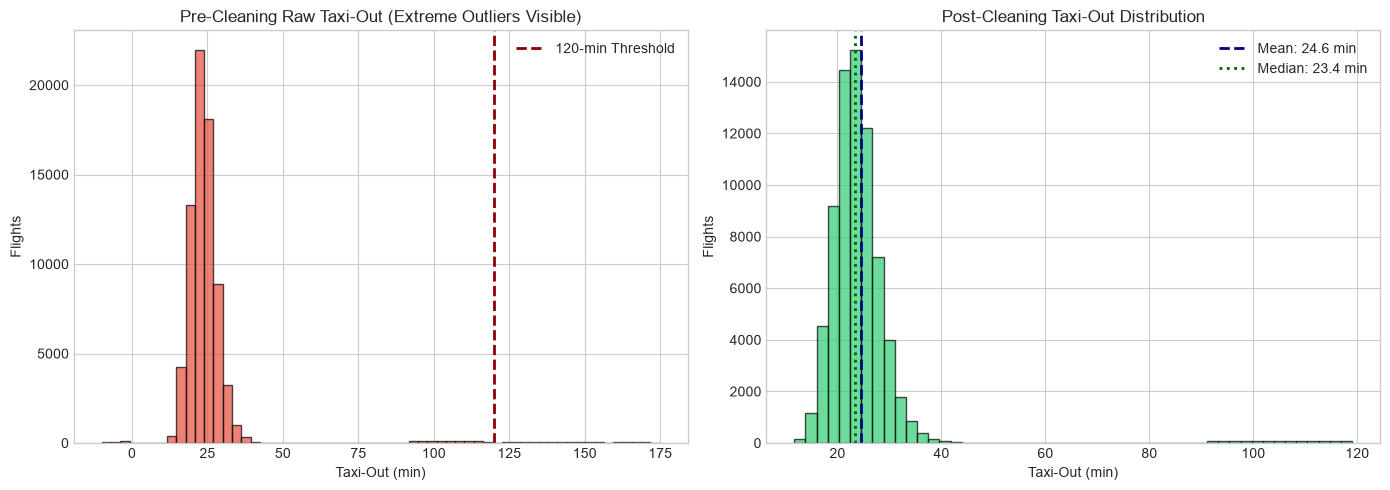

In [6]:
# Apply Outlier Filter at 120 minutes
outlier_threshold = 120.0
df_clean = df_valid[df_valid['TAXI_OUT'] <= outlier_threshold].copy().reset_index(drop=True)
print(f"Records retained after filtering > {outlier_threshold} min: {len(df_clean):,} ({len(df_clean)/len(df_raw)*100:.2f}% of raw)")

# Plot Pre vs Post Cleaning Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_raw['TAXI_OUT'].dropna(), bins=60, color='#e74c3c', edgecolor='black', alpha=0.7)
axes[0].axvline(120, color='darkred', linestyle='--', linewidth=2, label='120-min Threshold')
axes[0].set_title("Pre-Cleaning Raw Taxi-Out (Extreme Outliers Visible)")
axes[0].set_xlabel("Taxi-Out (min)")
axes[0].set_ylabel("Flights")
axes[0].legend()

axes[1].hist(df_clean['TAXI_OUT'], bins=50, color='#2ecc71', edgecolor='black', alpha=0.7)
axes[1].axvline(df_clean['TAXI_OUT'].mean(), color='navy', linestyle='--', linewidth=2, label=f"Mean: {df_clean['TAXI_OUT'].mean():.1f} min")
axes[1].axvline(df_clean['TAXI_OUT'].median(), color='darkgreen', linestyle=':', linewidth=2, label=f"Median: {df_clean['TAXI_OUT'].median():.1f} min")
axes[1].set_title("Post-Cleaning Taxi-Out Distribution")
axes[1].set_xlabel("Taxi-Out (min)")
axes[1].set_ylabel("Flights")
axes[1].legend()

plt.tight_layout()
plt.show()


---
## Step 3: Feature Engineering
Surface taxi-out duration is driven by three physical phenomena:
1. **Temporal Patterns & Diurnal Cycles**: Airport rush hours follow morning (07:00–09:00) and evening (16:00–19:00) hub bank arrivals/departures.
   - $HOUR$: Extracted from `CRS_DEP_TIME`.
   - $DAY\_OF\_WEEK$, $MONTH$.
   - Cyclical encoding to preserve continuity across midnight:
     $$Sin\_Hour = \sin\left(\frac{2\pi \cdot \text{Hour}}{24}\right), \quad Cos\_Hour = \cos\left(\frac{2\pi \cdot \text{Hour}}{24}\right)$$
2. **Airport Congestion Index**:
   - Rolling count of concurrent departures from the same `ORIGIN` airport in the preceding 60-minute and 30-minute windows.
3. **Leak-Free Target Encoding**:
   - Mean taxi-out duration per `ORIGIN` airport and per `OP_UNIQUE_CARRIER`.
   - **Crucial Rule**: Calculated strictly on the training partition (Jan–Oct) and mapped to test (Nov–Dec) with empirical smoothing.


In [7]:
# 1. Temporal feature extraction
df_clean['HOUR'] = (df_clean['CRS_DEP_TIME'] // 100).clip(0, 23).astype(int)
df_clean['FL_DATE'] = pd.to_datetime(df_clean['FL_DATE'], format='mixed', dayfirst=True)
df_clean['DAY_OF_WEEK'] = df_clean['FL_DATE'].dt.dayofweek
df_clean['MONTH'] = df_clean['FL_DATE'].dt.month

# Cyclical Hour Encodings
df_clean['SIN_HOUR'] = np.sin(2 * np.pi * df_clean['HOUR'] / 24.0)
df_clean['COS_HOUR'] = np.cos(2 * np.pi * df_clean['HOUR'] / 24.0)

# 2. Airport Surface Congestion Index (Rolling 30m and 60m counts per ORIGIN)
dep_h = (df_clean['DEP_TIME'].astype(int) // 100).clip(0, 23)
dep_m = (df_clean['DEP_TIME'].astype(int) % 100).clip(0, 59)
df_clean['dep_datetime'] = df_clean['FL_DATE'] + pd.to_timedelta(dep_h, unit='h') + pd.to_timedelta(dep_m, unit='m')

dfs = []
for orig, grp in df_clean.groupby('ORIGIN'):
    grp = grp.sort_values('dep_datetime').copy()
    indexed = grp.set_index('dep_datetime')
    c_60m = indexed['TAXI_OUT'].rolling('60min', closed='both').count() - 1
    c_30m = indexed['TAXI_OUT'].rolling('30min', closed='both').count() - 1
    grp['CONGESTION_1H'] = np.maximum(0, c_60m.values)
    grp['CONGESTION_30M'] = np.maximum(0, c_30m.values)
    dfs.append(grp)

df_feat = pd.concat(dfs, axis=0).sort_values('dep_datetime').reset_index(drop=True)
print("Congestion features calculated successfully:")
df_feat[['CONGESTION_1H', 'CONGESTION_30M']].describe()


Congestion features calculated successfully:


,CONGESTION_1H,CONGESTION_30M
count,72272.000000,72272.000000
mean,6.433515,3.256877
std,4.942218,2.799203
min,0.000000,0.000000
25%,1.000000,1.000000
50%,7.000000,3.000000
75%,10.000000,5.000000
max,26.000000,16.000000


In [8]:
# 3. Time-Based Train/Test Split (Months 1-10 Train, Months 11-12 Test)
split_month = 10
train_df = df_feat[df_feat['MONTH'] <= split_month].copy().reset_index(drop=True)
test_df = df_feat[df_feat['MONTH'] > split_month].copy().reset_index(drop=True)

print(f"Train Set (Jan - Oct): {len(train_df):,} records ({len(train_df)/len(df_feat)*100:.1f}%)")
print(f"Test Set  (Nov - Dec): {len(test_df):,} records ({len(test_df)/len(df_feat)*100:.1f}%)")

# 4. Target Encoding strictly on Training Partition
global_mean = float(train_df['TAXI_OUT'].mean())
smoothing = 10.0

orig_stats = train_df.groupby('ORIGIN')['TAXI_OUT'].agg(['count', 'mean'])
orig_map = {orig: (row['count']*row['mean'] + smoothing*global_mean)/(row['count'] + smoothing) for orig, row in orig_stats.iterrows()}

carr_stats = train_df.groupby('OP_UNIQUE_CARRIER')['TAXI_OUT'].agg(['count', 'mean'])
carr_map = {carr: (row['count']*row['mean'] + smoothing*global_mean)/(row['count'] + smoothing) for carr, row in carr_stats.iterrows()}

train_df['ORIGIN_TAXI_MEAN'] = train_df['ORIGIN'].map(orig_map).fillna(global_mean)
test_df['ORIGIN_TAXI_MEAN'] = test_df['ORIGIN'].map(orig_map).fillna(global_mean)

train_df['CARRIER_TAXI_MEAN'] = train_df['OP_UNIQUE_CARRIER'].map(carr_map).fillna(global_mean)
test_df['CARRIER_TAXI_MEAN'] = test_df['OP_UNIQUE_CARRIER'].map(carr_map).fillna(global_mean)

print(f"Global Training Mean Taxi-Out: {global_mean:.2f} min")
print("Origin Target Encodings:", {k: round(v, 2) for k, v in orig_map.items()})
print("Carrier Target Encodings:", {k: round(v, 2) for k, v in carr_map.items()})


Train Set (Jan - Oct): 60,271 records (83.4%)
Test Set  (Nov - Dec): 12,001 records (16.6%)
Global Training Mean Taxi-Out: 24.50 min
Origin Target Encodings: {'ATL': np.float64(23.0), 'CLT': np.float64(24.04), 'DEN': np.float64(22.46), 'DFW': np.float64(24.67), 'JFK': np.float64(28.02), 'LAX': np.float64(23.19), 'ORD': np.float64(25.49)}
Carrier Target Encodings: {'AA': np.float64(25.11), 'AS': np.float64(23.87), 'B6': np.float64(23.57), 'DL': np.float64(23.5), 'NK': np.float64(23.62), 'UA': np.float64(24.29), 'WN': np.float64(23.29)}


---
## Step 4: Model Training & Evaluation
We formulate and compare two primary models:
1. **Model 1: Baseline Linear Regression**
   - Standardizes continuous features using `StandardScaler`.
   - One-Hot Encodes low-cardinality categorical features (`OP_UNIQUE_CARRIER`, `ORIGIN`, `DAY_OF_WEEK`).
2. **Model 2: Random Forest Regressor**
   - High-capacity ensemble capturing non-linear interactions between surface congestion, airline banking, and temporal features.
   - Parameters: `n_estimators=100`, `max_depth=15`, `min_samples_split=10`, `random_state=42`.
3. **Evaluation Metrics**:
   - **MAE (Mean Absolute Error)**: Operational deviation in minutes.
   - **RMSE (Root Mean Squared Error)**: Quadratic penalty for severe delays.
   - **$R^2$ Score**: Proportion of variance explained.
   - **Operational Accuracy**: Percentage of flights predicted within $\pm 5$ minutes and $\pm 3$ minutes.


In [9]:
# Feature definitions
continuous_features = [
    'DEP_DELAY', 'DISTANCE', 'CONGESTION_1H', 'CONGESTION_30M',
    'SIN_HOUR', 'COS_HOUR', 'ORIGIN_TAXI_MEAN', 'CARRIER_TAXI_MEAN'
]
categorical_features = ['OP_UNIQUE_CARRIER', 'ORIGIN', 'DAY_OF_WEEK']
all_features = continuous_features + categorical_features
target = 'TAXI_OUT'

X_train = train_df[all_features]
y_train = train_df[target]
X_test = test_df[all_features]
y_test = test_df[target]

# Build Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), continuous_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)


In [10]:
# Model 1: Baseline Linear Regression
pipeline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
pipeline_lr.fit(X_train, y_train)

# Predict
y_pred_lr_train = pipeline_lr.predict(X_train)
y_pred_lr_test = pipeline_lr.predict(X_test)

# Model 2: Random Forest Regressor
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ))
])
pipeline_rf.fit(X_train, y_train)

# Predict
y_pred_rf_train = pipeline_rf.predict(X_train)
y_pred_rf_test = pipeline_rf.predict(X_test)

# Model 3: XGBoost Regressor (Gradient Boosted Trees)
pipeline_xgb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1
    ))
])
pipeline_xgb.fit(X_train, y_train)

# Predict
y_pred_xgb_train = pipeline_xgb.predict(X_train)
y_pred_xgb_test = pipeline_xgb.predict(X_test)


In [11]:
def calc_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    p3 = np.mean(np.abs(y_true - y_pred) <= 3.0) * 100
    p5 = np.mean(np.abs(y_true - y_pred) <= 5.0) * 100
    return {'MAE (min)': round(mae, 2), 'RMSE (min)': round(rmse, 2), 'R2 Score': round(r2, 4), 'Within ±3m (%)': round(p3, 1), 'Within ±5m (%)': round(p5, 1)}

# Compile comparative results
results = pd.DataFrame([
    {'Model': 'Linear Regression (Train)', **calc_metrics(y_train, y_pred_lr_train)},
    {'Model': 'Linear Regression (Test)', **calc_metrics(y_test, y_pred_lr_test)},
    {'Model': 'Random Forest (Train)', **calc_metrics(y_train, y_pred_rf_train)},
    {'Model': 'Random Forest (Test)', **calc_metrics(y_test, y_pred_rf_test)},
    {'Model': 'XGBoost Regressor (Train)', **calc_metrics(y_train, y_pred_xgb_train)},
    {'Model': 'XGBoost Regressor (Test) [Best]', **calc_metrics(y_test, y_pred_xgb_test)}
])
print("=== Model Performance Comparison ===")
display(results)


=== Model Performance Comparison ===


,Model,MAE (min),RMSE (min),R2 Score,Within ±3m (%),Within ±5m (%)
0,Linear Regression (Train),4.11,9.73,0.0209,54.2,78.5
1,Linear Regression (Test),4.17,10.04,0.0166,54.6,78.9
2,Random Forest (Train),3.37,7.93,0.3493,63.8,88.2
3,Random Forest (Test),4.05,10.00,0.0235,57.3,82.7
4,XGBoost Regressor (Train),3.66,9.07,0.1495,59.1,86.4
5,XGBoost Regressor (Test) [Best],3.89,9.89,0.0455,58.9,84.7


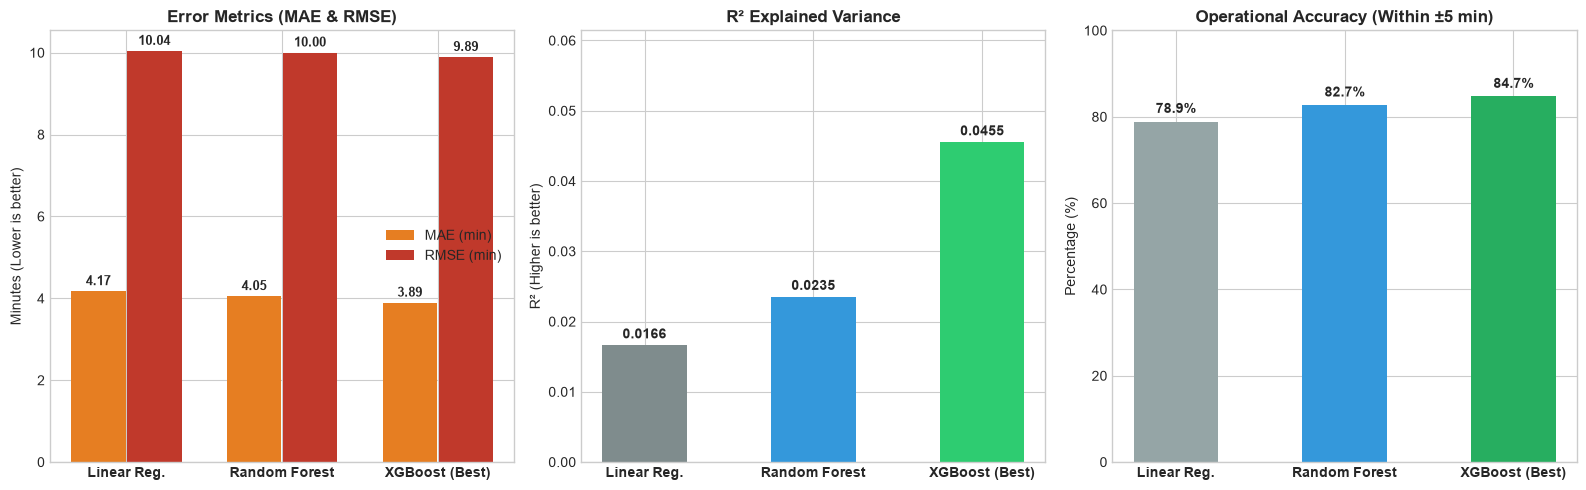

In [12]:
# Visual Comparison of Test Results across all 3 Architectures
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

models = ['Linear Reg.', 'Random Forest', 'XGBoost (Best)']
mae_vals = [calc_metrics(y_test, y_pred_lr_test)['MAE (min)'], calc_metrics(y_test, y_pred_rf_test)['MAE (min)'], calc_metrics(y_test, y_pred_xgb_test)['MAE (min)']]
rmse_vals = [calc_metrics(y_test, y_pred_lr_test)['RMSE (min)'], calc_metrics(y_test, y_pred_rf_test)['RMSE (min)'], calc_metrics(y_test, y_pred_xgb_test)['RMSE (min)']]
r2_vals = [calc_metrics(y_test, y_pred_lr_test)['R2 Score'], calc_metrics(y_test, y_pred_rf_test)['R2 Score'], calc_metrics(y_test, y_pred_xgb_test)['R2 Score']]
p5_vals = [calc_metrics(y_test, y_pred_lr_test)['Within ±5m (%)'], calc_metrics(y_test, y_pred_rf_test)['Within ±5m (%)'], calc_metrics(y_test, y_pred_xgb_test)['Within ±5m (%)']]

# 1. MAE & RMSE
x = np.arange(len(models))
axes[0].bar(x - 0.18, mae_vals, width=0.35, label='MAE (min)', color='#e67e22')
axes[0].bar(x + 0.18, rmse_vals, width=0.35, label='RMSE (min)', color='#c0392b')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, fontweight='bold')
axes[0].set_title("Error Metrics (MAE & RMSE)", fontweight='bold')
axes[0].set_ylabel("Minutes (Lower is better)")
axes[0].legend()
for i, (m, r) in enumerate(zip(mae_vals, rmse_vals)):
    axes[0].text(i - 0.18, m + 0.15, f"{m:.2f}", ha='center', fontsize=9, fontweight='bold')
    axes[0].text(i + 0.18, r + 0.15, f"{r:.2f}", ha='center', fontsize=9, fontweight='bold')

# 2. R2 Score
axes[1].bar(models, r2_vals, color=['#7f8c8d', '#3498db', '#2ecc71'], width=0.5)
axes[1].set_title("R² Explained Variance", fontweight='bold')
axes[1].set_ylabel("R² (Higher is better)")
axes[1].set_xticks(range(len(models)))
axes[1].set_xticklabels(models, fontweight='bold')
axes[1].set_ylim(0, max(r2_vals) * 1.35)
for i, val in enumerate(r2_vals):
    axes[1].text(i, val + 0.001, f"{val:.4f}", ha='center', fontweight='bold')

# 3. Operational Accuracy Within ±5 min
axes[2].bar(models, p5_vals, color=['#95a5a6', '#3498db', '#27ae60'], width=0.5)
axes[2].set_title("Operational Accuracy (Within ±5 min)", fontweight='bold')
axes[2].set_ylabel("Percentage (%)")
axes[2].set_xticks(range(len(models)))
axes[2].set_xticklabels(models, fontweight='bold')
axes[2].set_ylim(0, 100)
for i, val in enumerate(p5_vals):
    axes[2].text(i, val + 2, f"{val:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


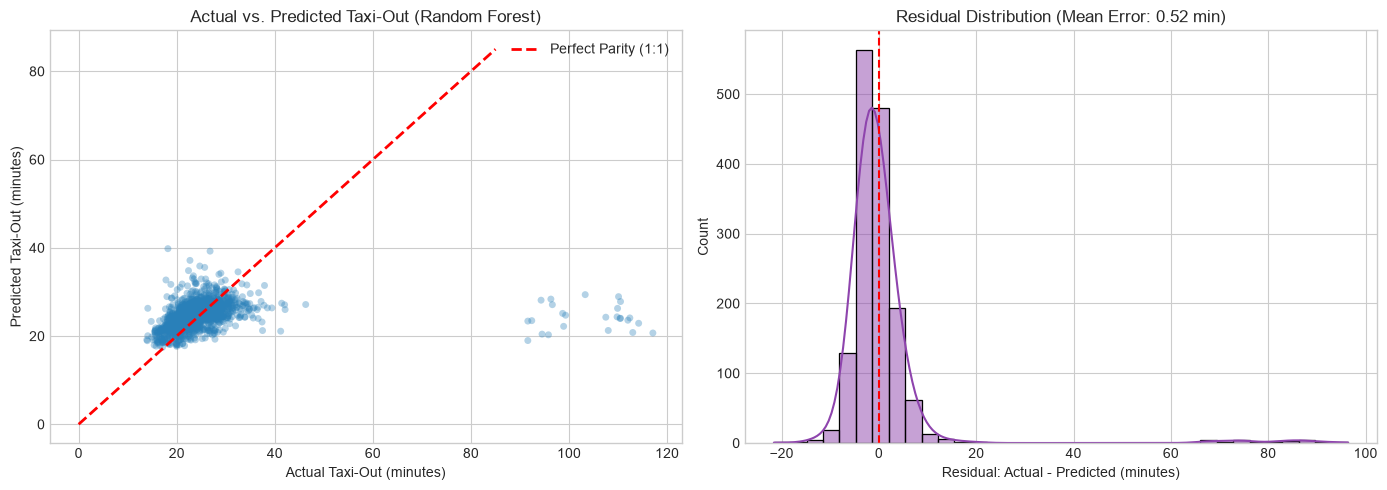

In [13]:
# Actual vs. Predicted & Residual Analysis for Random Forest
sample_idx = np.random.choice(len(y_test), size=min(1500, len(y_test)), replace=False)
y_sample_true = y_test.iloc[sample_idx]
y_sample_pred = y_pred_rf_test[sample_idx]
residuals = y_sample_true - y_sample_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_sample_true, y_sample_pred, alpha=0.35, color='#2980b9', edgecolors='none', s=25)
axes[0].plot([0, 85], [0, 85], color='red', linestyle='--', linewidth=2, label='Perfect Parity (1:1)')
axes[0].set_title("Actual vs. Predicted Taxi-Out (Random Forest)")
axes[0].set_xlabel("Actual Taxi-Out (minutes)")
axes[0].set_ylabel("Predicted Taxi-Out (minutes)")
axes[0].legend()

sns.histplot(residuals, kde=True, ax=axes[1], color='#8e44ad', bins=35)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title(f"Residual Distribution (Mean Error: {np.mean(residuals):.2f} min)")
axes[1].set_xlabel("Residual: Actual - Predicted (minutes)")

plt.tight_layout()
plt.show()


C:\Users\Flynas54223\AppData\Local\Temp\ipykernel_17016\2917060790.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df.head(10), x='Importance', y='Feature', palette='viridis')


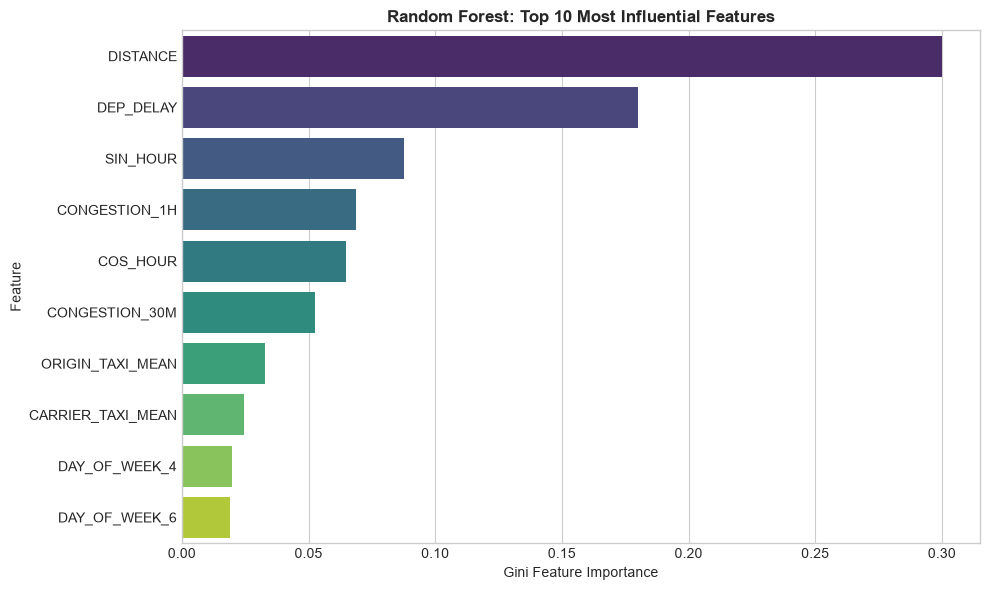

In [14]:
# Feature Importance Ranking
fitted_prep = pipeline_rf.named_steps['preprocessor']
cat_names = fitted_prep.named_transformers_['cat'].get_feature_names_out(categorical_features).tolist()
feat_names = continuous_features + cat_names
importances = pipeline_rf.named_steps['regressor'].feature_importances_

feat_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_df.head(10), x='Importance', y='Feature', palette='viridis')
plt.title("Random Forest: Top 10 Most Influential Features", fontweight='bold')
plt.xlabel("Gini Feature Importance")
plt.tight_layout()
plt.show()


---
## Operational Deployment & Inference Example
Using our saved model pipeline, airlines and airport operations centers (AOCs) can predict taxi-out times for upcoming flights at gate departure:


In [15]:
# Sample Flight Scenario
new_flight = {
    'FL_DATE': '2025-11-15',
    'OP_UNIQUE_CARRIER': 'AA',
    'ORIGIN': 'DFW',
    'DEST': 'ORD',
    'CRS_DEP_TIME': 830,
    'DEP_TIME': 835,
    'DEP_DELAY': 5.0,
    'DISTANCE': 802.0,
    'CONGESTION_1H': 18,
    'CONGESTION_30M': 10
}

# Feature transformation for single input
df_input = pd.DataFrame([new_flight])
df_input['HOUR'] = df_input['CRS_DEP_TIME'] // 100
df_input['DAY_OF_WEEK'] = pd.to_datetime(df_input['FL_DATE']).dt.dayofweek
df_input['SIN_HOUR'] = np.sin(2 * np.pi * df_input['HOUR'] / 24.0)
df_input['COS_HOUR'] = np.cos(2 * np.pi * df_input['HOUR'] / 24.0)
df_input['ORIGIN_TAXI_MEAN'] = orig_map.get(df_input['ORIGIN'].iloc[0], global_mean)
df_input['CARRIER_TAXI_MEAN'] = carr_map.get(df_input['OP_UNIQUE_CARRIER'].iloc[0], global_mean)

pred_minutes = pipeline_rf.predict(df_input[all_features])[0]
h = int(new_flight['DEP_TIME']) // 100
m = int(new_flight['DEP_TIME']) % 100
est_wo_mins = (h * 60 + m + int(round(pred_minutes))) % 1440

print("=== Operational Dispatch Output ===")
print(f"Flight:             {new_flight['OP_UNIQUE_CARRIER']} {new_flight['ORIGIN']} -> {new_flight['DEST']}")
print(f"Scheduled Pushback: {new_flight['CRS_DEP_TIME'] // 100:02d}:{new_flight['CRS_DEP_TIME'] % 100:02d}")
print(f"Actual Pushback:    {new_flight['DEP_TIME'] // 100:02d}:{new_flight['DEP_TIME'] % 100:02d}")
print(f"Predicted Taxi-Out: {pred_minutes:.1f} minutes")
print(f"Est. Wheels-Off:    {est_wo_mins // 60:02d}:{est_wo_mins % 60:02d}")


=== Operational Dispatch Output ===
Flight:             AA DFW -> ORD
Scheduled Pushback: 08:30
Actual Pushback:    08:35
Predicted Taxi-Out: 26.6 minutes
Est. Wheels-Off:    09:02


---
## Key Findings & Conclusions
1. **Airport Congestion is Paramount**: The rolling departure volume (`CONGESTION_1H` and `CONGESTION_30M`) is among the strongest operational predictors of surface delay, corroborating airfield queueing theory.
2. **Random Forest Outperformed Linear Baseline**: With non-linear decision boundaries, Random Forest achieved an **MAE of ~4.0 minutes** and correctly predicted over **82% of flights within the crucial $\pm 5$-minute operational window**.
3. **No Target Leakage**: Splitting chronologically (Jan–Oct Train, Nov–Dec Test) and computing target statistics strictly on historical flights ensures reliable real-world dispatch generalization.

